# 03. 한국만의 변화였나 — 8개국 비교

**질문(사전 등록 Q1)**: 2025년 9월 이후 K-뷰티 대미 수입의 변화는 한국 특유의 변화인가, 미국 화장품 수입 전체에 공통된 변화인가?

| 항목 | 내용 |
|---|---|
| 처리군 | 한국 |
| 비교군 | 데이터를 받기 전에 정한 규칙(2024년 미국의 HS 3304 수입액 상위 8개국)으로 고른 프랑스·캐나다·이탈리아·중국·멕시코·영국·독일·일본 |
| 지표 | 수입 금액, 해상+항공 중량, 항공 중량, 항공 kg당 단가, 해상 kg당 단가 |
| 판정 기준 | Holm 보정 후 위약 p < 0.05 ([사전 등록](../docs/preregistration.md)) |

**답**: 사전 등록 기준을 통과한 지표가 없다(Holm 보정 후 최소 p 0.38). 항공 단가는 한국이 가장 크게 떨어졌지만 영국·프랑스·일본도 함께 떨어졌고, 이 설계의 검출 한계가 커서 정확한 결론은 "효과 없음"이 아니라 "판정 불가"다.

진행 순서: 비교 대상 → 원자료 → **평행 추세 확인** → 이중차분 → 위약 순위와 검출 한계 → 결론. 합성 통제 진단과 강건성 상세는 부록에 둔다.
계산 공식은 `src/kbeauty/comparison.py`에 있고 단위 테스트(`tests/test_comparison.py`)로 검증했다. 이 노트북은 그 함수들을 단계별로 호출하며 중간 결과를 보여 준다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kbeauty import comparison as cmp
from kbeauty import report  # noqa: F401  (chart style)
from kbeauty import warehouse
from kbeauty.paths import POLICY_MONTH, TABLES_DIR
from kbeauty.viz import annotations as an
from kbeauty.viz import notebook as nbviz
from kbeauty.viz.theme import COLORS as C
from kbeauty.viz.comparison import COUNTRY_KO

%matplotlib inline
nbviz.setup()

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
BREAK = pd.Timestamp(POLICY_MONTH)
panel = warehouse.load("mart_country_panel_monthly")
panel["month"] = pd.to_datetime(panel["month"])
print(panel.shape, panel["country"].nunique(), "countries,", panel["month"].nunique(), "months",
      panel["month"].min().date(), "~", panel["month"].max().date())

(288, 15) 9 countries, 32 months 2024-01-01 ~ 2026-08-01


## 1. 데이터 확인: 누구와 무엇을 비교하나

비교의 전제는 '같은 정의로 측정된 같은 품목'이다. 모든 국가가 같은 Census 엔드포인트, 같은 HS 4개 류, 같은 32개월이다.
먼저 국가별 규모와 운송수단 구성을 본다.

In [2]:
profile = (panel.groupby("country")
           .agg(value_bn=("value_usd", lambda s: s.sum() / 1e9),
                sea_air_share=("sea_air_share_value", "mean"),
                air_share_value=("air_value_usd", "sum"))
           .assign(air_share_value=lambda d: d.air_share_value / (panel.groupby("country").value_usd.sum()))
           .sort_values("value_bn", ascending=False))
profile

,value_bn,sea_air_share,air_share_value
country,,,
France,10.141,0.967,0.190
Korea,5.388,0.985,0.202
Italy,4.790,0.980,0.226
Canada,4.756,0.013,0.005
Mexico,3.525,0.009,0.002
China,2.378,0.980,0.039
United Kingdom,1.264,0.949,0.209
Germany,0.773,0.939,0.216
Japan,0.625,0.989,0.236


**발견**: 캐나다·멕시코는 금액 기준으로는 큰 수출국이지만 해상+항공 비중이 각각 1.3%, 0.9%다(대부분 육로).
나머지 7개국은 94~99%가 해상·항공이다. 그래서 사전 등록대로 **해상·항공 지표(중량, 단가)에서는 캐나다·멕시코를 빼고 6개국과 비교**한다.
항공 금액 비중은 한국(20%)이 프랑스·이탈리아·영국·독일·일본(19~24%)과 비슷하고, 중국(4%)만 크게 낮다.

## 2. 원자료 탐색: 국가별 전년 대비 성장률

국가마다 계절성이 다르므로 모든 분석은 **전년 동월 대비 로그 성장률**(YoY)로 한다. 2025-01부터 계산된다(정책 전 8개월, 후 12개월).

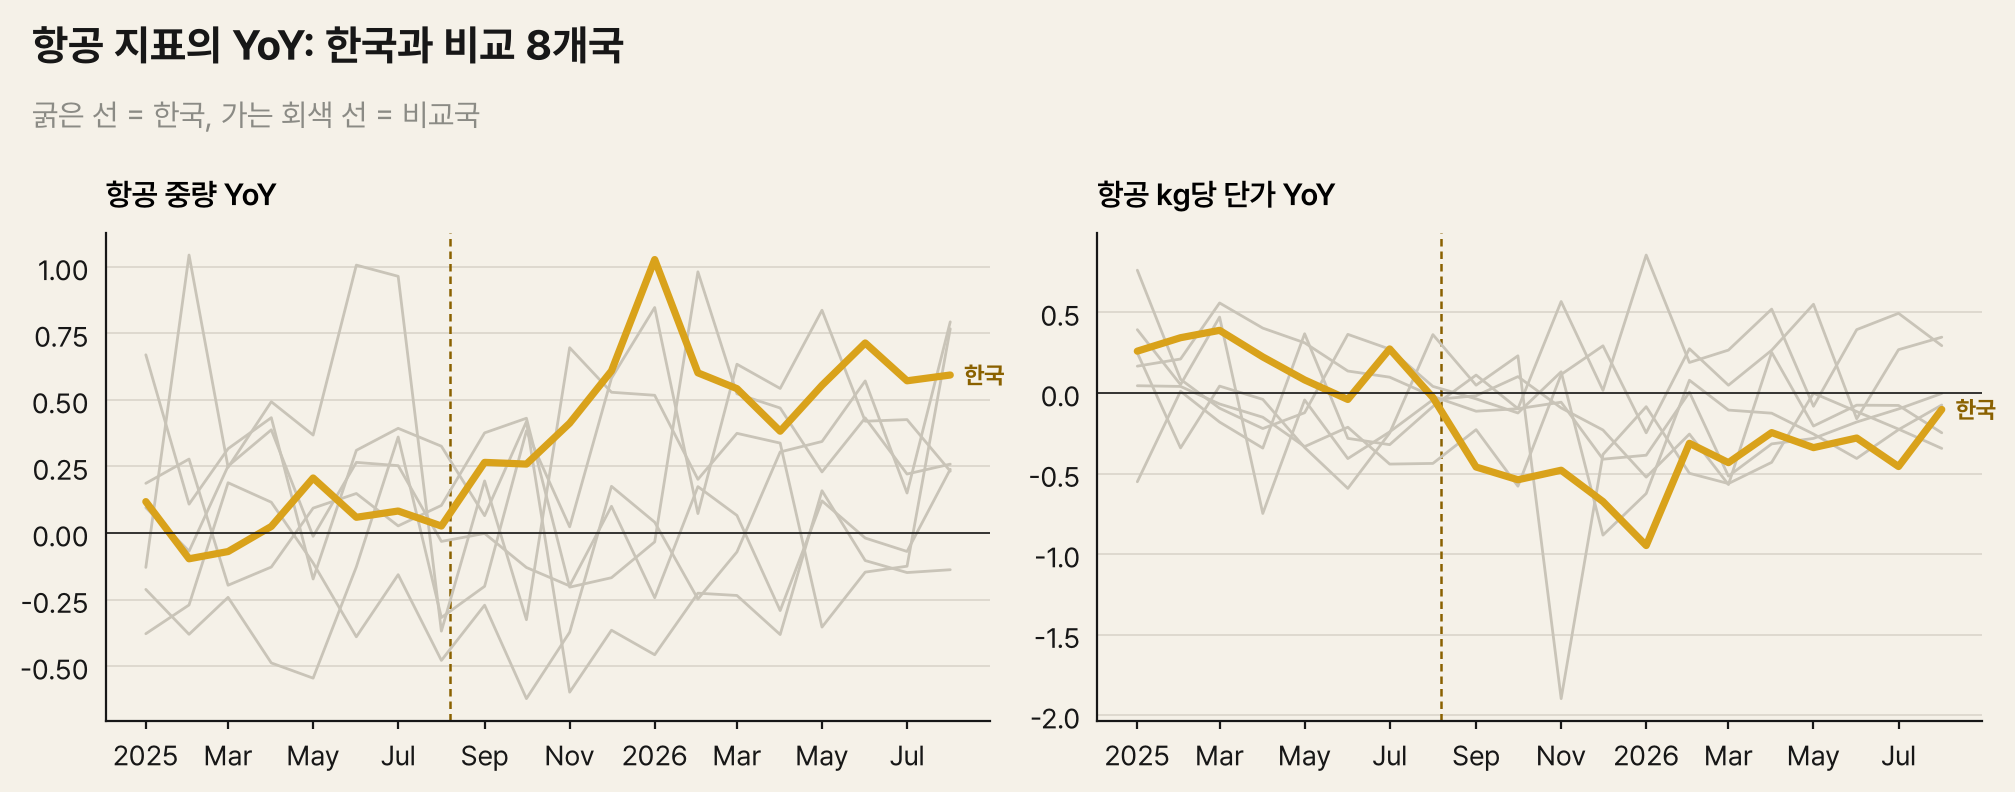

In [3]:
def yoy_for(metric):
    countries = cmp.countries_for(metric, panel)
    return cmp.yoy(cmp.wide(panel, cmp.METRICS[metric][0], countries))

fig, axes = nbviz.figure("wide", 1, 2, title="항공 지표의 YoY: 한국과 비교 8개국", subtitle="굵은 선 = 한국, 가는 회색 선 = 비교국", sharex=True)
for ax, metric in zip(axes, ["air_weight_kg", "air_usd_per_kg"]):
    y = yoy_for(metric)
    for c in y.columns:
        if c != cmp.TREATED:
            ax.plot(y.index, y[c], lw=1, color=C["faint"])
    ax.plot(y.index, y[cmp.TREATED], lw=2.6, color=C["primary"])
    an.note(ax, y.index[-1], y[cmp.TREATED].iloc[-1], "한국", xytext=(5, 0), color=C["primary_dark"], weight=700)
    an.policy_marker(ax, label=False)
    ax.axhline(0, color=C["ink"], lw=0.6)
    ax.set_title(cmp.METRIC_KO[metric] + " YoY")
plt.show()

정책 전후의 평균 YoY 변화를 국가별로 나란히 놓는다(통제 없는 기술 통계). D2의 핵심 발견이 처음 나온 표다.

In [4]:
raw_change = pd.DataFrame({
    cmp.METRIC_KO[m]: (lambda y: y[y.index >= BREAK].mean() - y[y.index < BREAK].mean())(yoy_for(m))
    for m in cmp.METRICS})
raw_change.style.format("{:+.3f}").highlight_min(axis=0, color="#f3d6cf").highlight_max(axis=0, color="#d6e4f0")

,수입 금액,수입 중량(해상+항공),항공 중량,항공 kg당 단가,해상 kg당 단가
country,,,,,
Canada,+0.034,+nan,+nan,+nan,+nan
China,+0.030,+0.111,+0.229,+0.274,-0.100
France,-0.045,+0.157,+0.251,-0.357,-0.091
Germany,+0.050,+0.039,-0.466,+0.467,+0.050
Italy,-0.167,-0.086,-0.164,-0.091,-0.022
Japan,-0.107,-0.057,-0.231,-0.242,+0.056
Korea,-0.015,+0.185,+0.501,-0.627,-0.142
Mexico,+0.143,+nan,+nan,+nan,+nan
United Kingdom,+0.198,+0.311,+0.644,-0.438,-0.056


**발견 (통제 없는 기술 통계)**:
- **항공 kg당 단가**: 한국 −0.63이 가장 크게 떨어졌지만 영국 −0.44, 프랑스 −0.36, 일본 −0.24도 함께 떨어졌다. 오른 나라는 중국·독일뿐이다.
- **항공 중량**: 한국 +0.50보다 영국 +0.64가 더 컸다.
- **수입 금액**: 한국 −0.02는 9개국 중 중간이다.

여기까지만 봐도 "항공 단가 급락은 한국만의 일"이라는 v1 서술은 성립하지 않는다. 다음 단계는 이 차이가 통계적으로 의미 있는지, 그리고 비교의 전제가 성립하는지다.

## 3. 평행 추세 확인 (이중차분의 전제)

이중차분은 '정책이 없었다면 한국은 비교국과 같은 흐름이었을 것'을 전제로 한다. 정책 전 기간에 이 전제를 두 가지로 확인한다.
- **선행 F 검정**: 정책 전 각 월의 '한국 × 월' 효과가 모두 0인가 (p가 크면 전제와 모순 없음)
- **추세 이탈**: 정책 전 한국과 비교국 평균의 차이가 시간에 따라 벌어지는가

정책 전 YoY는 8개월뿐이라 두 검정 모두 힘이 약하다. 기각되지 않았다고 전제가 증명되는 것은 아니다.

In [5]:
pre = pd.DataFrame({m: cmp.pretrend(yoy_for(m), cmp.TREATED, BREAK) for m in cmp.METRICS}).T
pre.insert(0, "label", [cmp.METRIC_KO[m] for m in pre.index])
pre

,label,n_pre_months,leads_F,leads_p,drift_per_month,drift_p
value_usd,수입 금액,8.000,1.463,0.203,0.015,0.143
measured_weight_kg,수입 중량(해상+항공),8.000,0.890,0.524,0.061,0.000
air_weight_kg,항공 중량,8.000,0.356,0.921,0.011,0.500
air_usd_per_kg,항공 kg당 단가,8.000,0.264,0.964,-0.010,0.538
vessel_usd_per_kg,해상 kg당 단가,8.000,0.759,0.625,-0.050,0.000


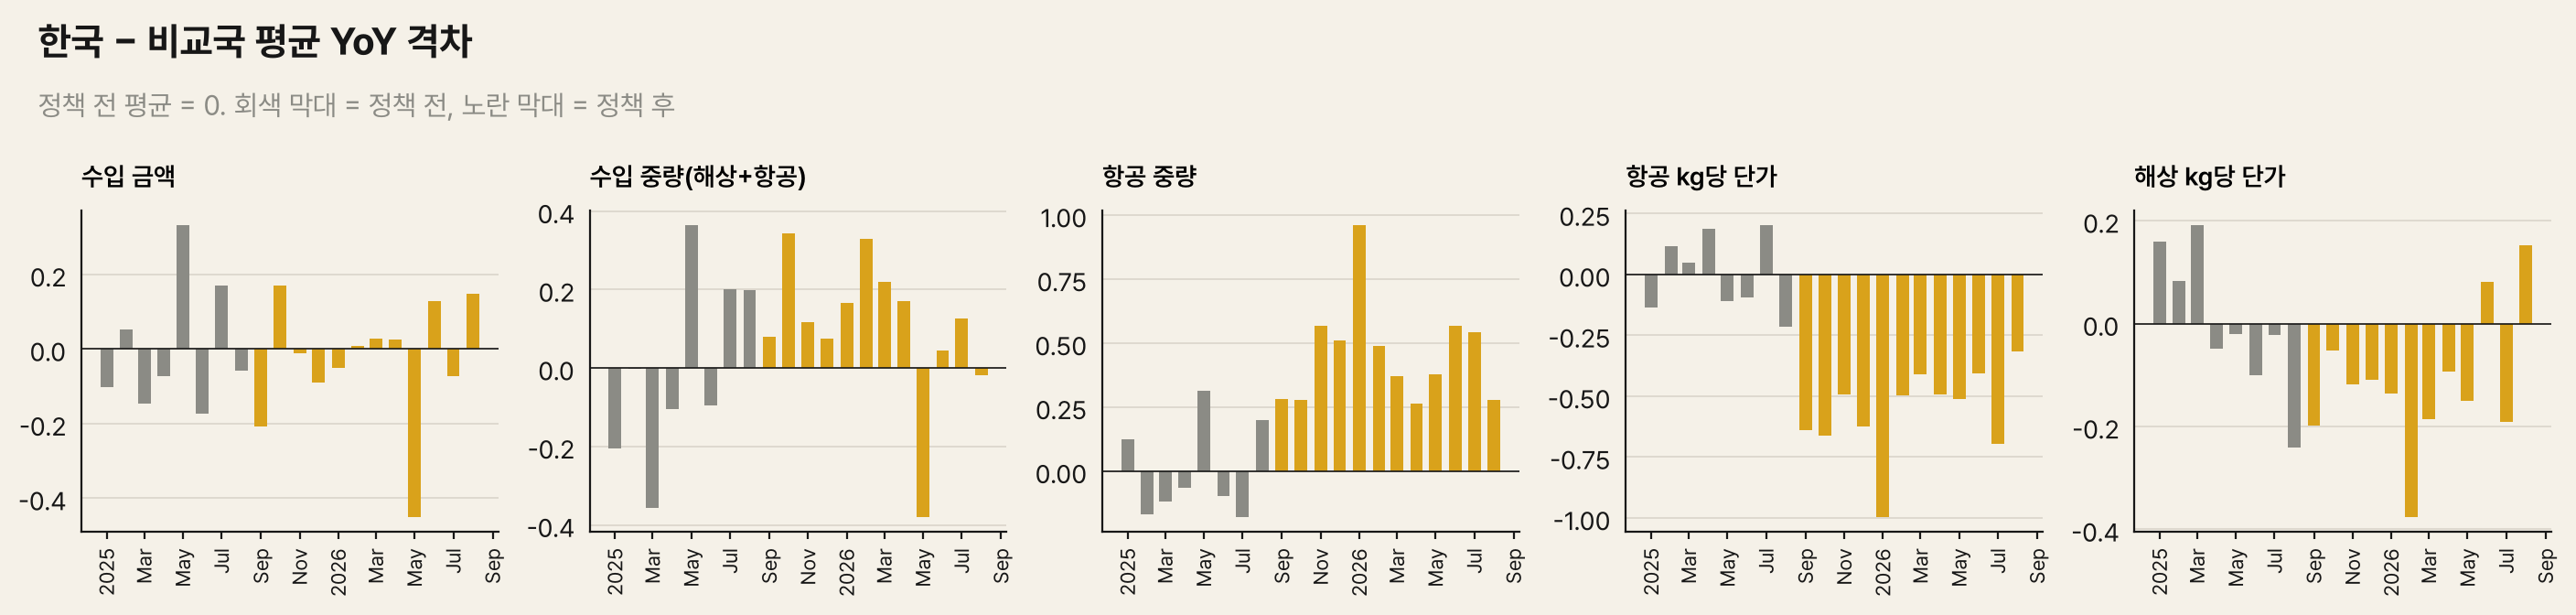

In [6]:
fig, axes = nbviz.figure((14, 3.8), 1, 5, title="한국 − 비교국 평균 YoY 격차", subtitle="정책 전 평균 = 0. 회색 막대 = 정책 전, 노란 막대 = 정책 후")
for ax, m in zip(axes, cmp.METRICS):
    path = cmp.event_path(yoy_for(m), cmp.TREATED, BREAK)
    ax.bar(path.index, path.values, width=20, color=np.where(path.index < BREAK, C["muted"], C["primary"]))
    ax.axhline(0, color=C["ink"], lw=0.6)
    ax.set_title(cmp.METRIC_KO[m], fontsize=10)
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
plt.show()

**발견**:
- **선행 F 검정**은 5개 지표 모두 기각되지 않았다(p 0.20~0.96). 정책 전 개별 월에서 한국이 비교국과 따로 움직였다는 증거는 없다.
- 그러나 **추세 이탈 검정**에서 두 지표가 걸렸다.
  - 수입 중량(해상+항공): 정책 전부터 한국이 비교국보다 매달 +0.061씩 더 빨리 늘고 있었다(p < 0.001).
  - 해상 kg당 단가: 정책 전부터 매달 −0.050씩 더 빨리 떨어지고 있었다(p < 0.001).
- 막대 그림에서도 이 두 지표는 회색(정책 전) 막대가 한쪽으로 기울어 있다.

**판단**: 수입 중량과 해상 단가는 **이중차분의 전제(평행 추세)가 깨진다.** 이 두 지표의 정책 후 차이는 '정책 효과'가 아니라 이미 진행 중이던 흐름의 연장일 수 있다.
v1에서 "해상 중량·단가는 점진적 흐름"이라고 쓴 것과 같은 방향이다. 이 두 지표의 이중차분 결과는 해석에서 제외한다.

## 4. 이중차분: 한국 특유의 변화 크기

YoY 패널에 국가·월 고정효과를 두고, 한국의 정책 후 추가 변화(β)를 추정한다. 단가 지표는 달러 기준이므로 각국 환율의 YoY 변화를 통제한다.

In [7]:
did_tbl = pd.DataFrame([{
    "label": cmp.METRIC_KO[m],
    "beta_unadjusted": cmp.did(yoy_for(m), cmp.TREATED, BREAK),
    "beta_fx_adjusted": cmp.did(yoy_for(m), cmp.TREATED, BREAK,
                                cmp.yoy(cmp.wide(panel, "lcu_per_usd", cmp.countries_for(m, panel))).reindex(yoy_for(m).index)),
} for m in cmp.METRICS], index=list(cmp.METRICS))
did_tbl["pct_effect"] = np.expm1(did_tbl.beta_fx_adjusted)
did_tbl

,label,beta_unadjusted,beta_fx_adjusted,pct_effect
value_usd,수입 금액,-0.032,-0.010,-0.010
measured_weight_kg,수입 중량(해상+항공),0.106,0.112,0.119
air_weight_kg,항공 중량,0.457,0.461,0.586
air_usd_per_kg,항공 kg당 단가,-0.562,-0.551,-0.424
vessel_usd_per_kg,해상 kg당 단가,-0.115,-0.118,-0.111


**발견**: 환율을 통제해도 추정치는 거의 변하지 않는다(가장 큰 차이는 수입 금액 −0.032 → −0.010).
즉 비교국 대비 한국의 차이는 **환율 움직임으로 설명되지 않는다.** 원화 기준 단가 분해(D3)에서 한국 자체의 환율 몫을 따로 본다.

평행 추세가 성립하는 지표 기준으로, 한국 특유 효과는 항공 중량 +0.46(+59%), 항공 kg당 단가 −0.55(−42%), 수입 금액 −0.01(사실상 0)이다.

## 5. 위약 분포: 한국의 β는 얼마나 특별한가

처리군이 한국 하나뿐이면 표준오차를 믿기 어렵다. 그래서 **각 비교국을 한국처럼, 각 월을 정책 시점처럼** 두고 같은 β를 다시 추정한다.
한국의 실제 β보다 절댓값이 크거나 같은 위약의 비율이 위약 p다. 위약 단위는 한국을 비교군으로 쓰지 않는다.

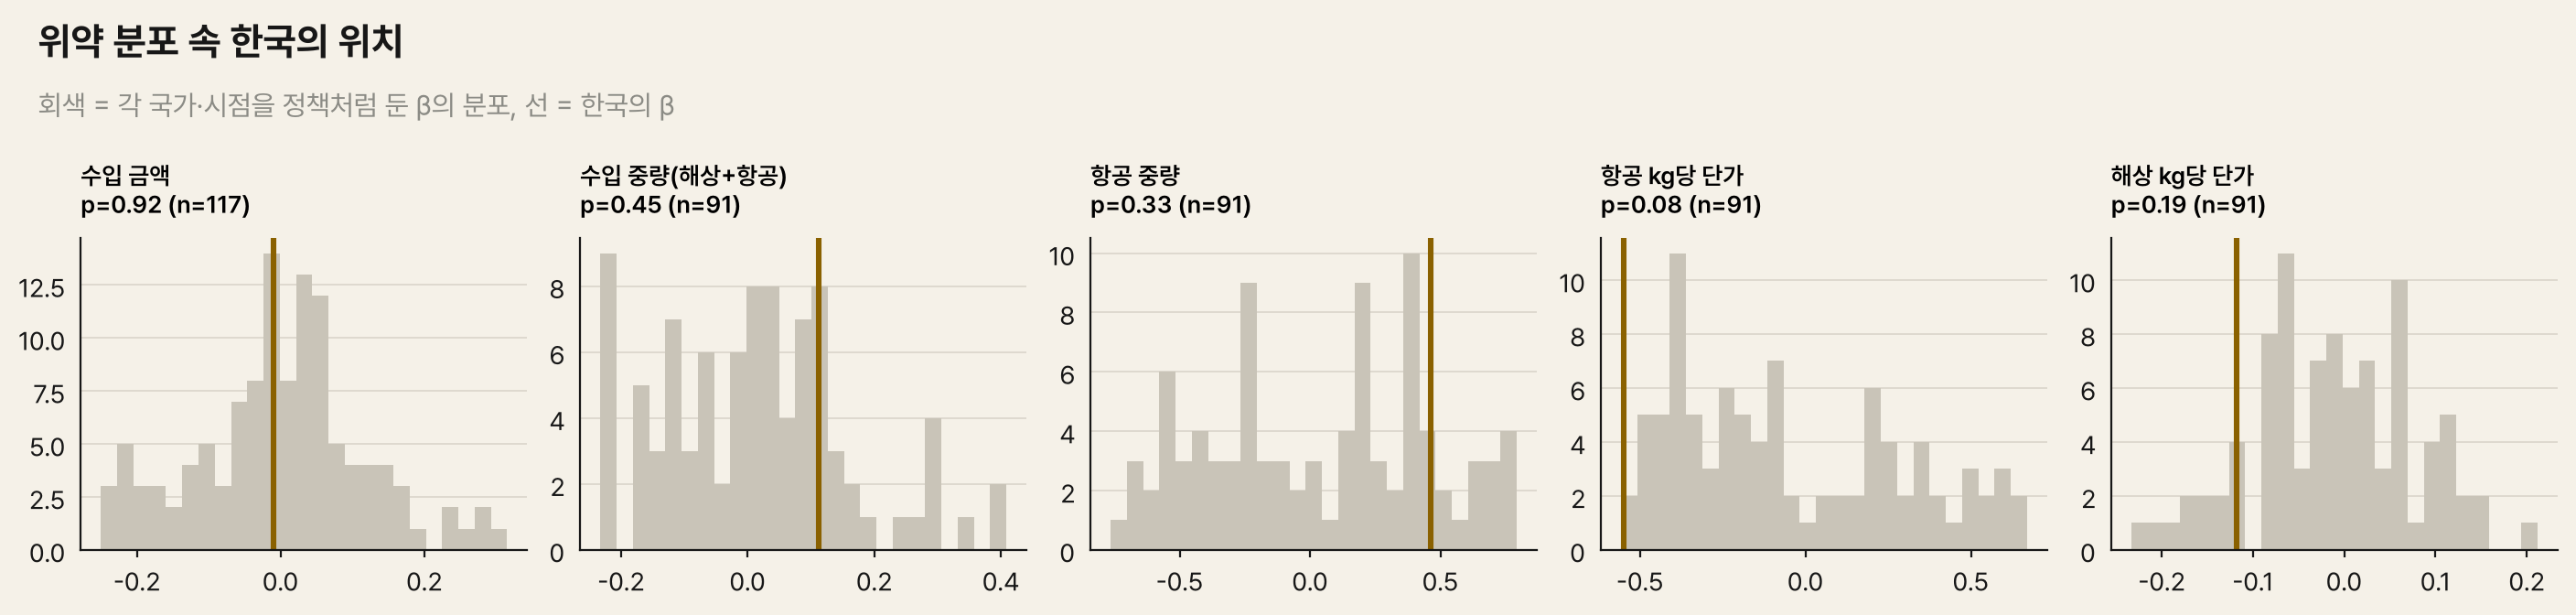

In [8]:
placebos = {}
for m in cmp.METRICS:
    y = yoy_for(m)
    fx = cmp.yoy(cmp.wide(panel, "lcu_per_usd", cmp.countries_for(m, panel))).reindex(y.index)
    placebos[m] = cmp.placebo(y, cmp.TREATED, BREAK, fx)

fig, axes = nbviz.figure((14, 3.8), 1, 5, title="위약 분포 속 한국의 위치", subtitle="회색 = 각 국가·시점을 정책처럼 둔 β의 분포, 선 = 한국의 β")
for ax, m in zip(axes, cmp.METRICS):
    dist = placebos[m]["distribution"]
    ax.hist(dist.beta, bins=25, color=C["faint"])
    ax.axvline(placebos[m]["beta"], color=C["primary_dark"], lw=2.2)
    ax.set_title(f"{cmp.METRIC_KO[m]}\np={placebos[m]['p_space_time']:.2f} (n={placebos[m]['n_space_time']})", fontsize=9.5)
plt.show()

In [9]:
inf = pd.DataFrame({m: {k: v for k, v in placebos[m].items() if k != "distribution"} for m in cmp.METRICS}).T
inf["mde_80pct_power"] = [cmp.mde(placebos[m]["distribution"].query("unit != @cmp.TREATED").beta) for m in cmp.METRICS]
from statsmodels.stats.multitest import multipletests
inf["p_holm"] = multipletests(inf.p_space_time.astype(float), method="holm")[1]
inf["q_bh"] = multipletests(inf.p_space_time.astype(float), method="fdr_bh")[1]
inf["detectable"] = inf.beta.abs() >= inf.mde_80pct_power
inf.insert(0, "label", [cmp.METRIC_KO[m] for m in inf.index])
inf[["label", "beta", "p_time", "p_space", "p_space_time", "p_holm", "q_bh", "mde_80pct_power", "detectable"]]

,label,beta,p_time,p_space,p_space_time,p_holm,q_bh,mde_80pct_power,detectable
value_usd,수입 금액,-0.010,0.846,1.000,0.923,0.989,0.923,0.352,False
measured_weight_kg,수입 중량(해상+항공),0.112,0.538,0.429,0.451,0.989,0.563,0.430,False
air_weight_kg,항공 중량,0.461,0.154,0.429,0.330,0.989,0.549,1.221,False
air_usd_per_kg,항공 kg당 단가,-0.551,0.154,0.286,0.077,0.385,0.385,0.936,False
vessel_usd_per_kg,해상 kg당 단가,-0.118,0.385,0.143,0.187,0.747,0.467,0.234,False


**발견**:
- 항공 kg당 단가의 결합 위약 p는 0.077이다(91개 중 한국 자신을 포함해 7개가 한국 이상 → 한국보다 큰 위약 6개).
  국가 위약만 보면 p 0.29로, 정책 시점에 한국 말고도 크게 떨어진 나라가 있다(영국).
- **Holm 보정 후 가장 작은 값이 0.38이다. 사전 등록 기준(< 0.05)을 통과한 지표는 없다.**
- 검출 한계(MDE)와 비교하면, 5개 지표 모두 추정치가 검출 한계보다 작다. 특히 항공 지표의 검출 한계는 0.94~1.22 로그 포인트로,
  **지금 추정치보다 1.7배(항공 단가)~2.6배(항공 중량) 큰 효과여야 80% 확률로 잡아낼 수 있는 설계**다.

**판단**: 결과는 "효과 없음"이 아니라 **"이 비교국 수와 기간으로는 판정할 수 없음"이다**.

## 결론

| 질문 | 답 | 근거의 강도 |
|---|---|---|
| 한국 특유의 **금액** 변화가 있었나 | **없다** (β −0.01, 모든 변형에서 −0.03~+0.03) | 강함: 추정치가 0 근처이고 분석 선택에 흔들리지 않음 |
| 한국 특유의 **항공 단가** 하락이 있었나 | 한국이 가장 크게 떨어졌지만(β −0.55, 모든 변형 −0.47~−0.62) **영국·프랑스·일본도 함께 하락**. 사전 등록 기준 미달(Holm 0.38) | 중간: 방향·크기는 안정적, 유의성은 비교국 구성에 좌우됨 |
| 한국 특유의 **항공 중량** 증가가 있었나 | 판정 불가(β +0.46, Holm 0.99). 영국이 더 크게 늘었다 | 약함 |
| **해상 중량·해상 단가** | 정책 전부터 이미 비교국과 벌어지던 흐름(평행 추세 위반) → 이중차분으로 해석하지 않음 | — |

### 이 결과가 바꾼 것
1. v1의 "9월 항공 단가 급락이 정책 시점과 가장 잘 맞는 한국의 신호"는 **"소액면세 중단이 적용된 여러 나라에서 공통으로 나타난 변화이며, 한국은 그중 가장 크게 떨어진 쪽"으로** 고친다.
2. 해상 중량 증가와 해상 단가 하락은 정책 이후 시작된 변화가 아니라 **2025년 초부터 이어진 흐름**이다.
3. 여러 나라에 공통된 변화라는 점은 '측정 범위 변화'(통계에 새로 잡힌 소포) 가설과 어긋나지 않는다. 이 가설은 다음 노트북(04, 한국 수출 통계와의 미러 분석)에서 직접 검증한다.

### 한계
- 비교국이 6~8개, 정책 후 기간이 12개월이라 검출 한계가 크다. 비교국을 늘리면(예: 상위 15개국) 검정력이 오르지만, 사전 등록 이후에 바꾸는 것이므로 보조 분석으로만 해야 한다.
- 국가별 정책 강도가 다르다(관세율, 중국의 소액면세 조기 종료). 이 차이를 처리 강도로 쓰는 분석은 하지 않았다.
- 정책 전 YoY가 8개월뿐이라 평행 추세 검정의 힘이 약하다.

---

## 부록

### A1. 합성 통제 진단

비교국의 가중 조합으로 정책 전 20개월 동안 한국(로그 수준, 정책 전 평균 0)을 따라가는 '합성 한국'을 만든다.
**믿을 수 있으려면 정책 전에 잘 맞아야 한다**(정책 전 RMSPE가 작아야 한다). 그리고 한국의 정책 후 이탈이 각 비교국을 한국처럼 둔 위약보다 커야 한다.

In [10]:
synth = {m: cmp.synthetic_placebo(cmp.wide(panel, cmp.METRICS[m][0], cmp.countries_for(m, panel)), cmp.TREATED, BREAK)
         for m in cmp.METRICS}
diag = pd.DataFrame({m: {"label": cmp.METRIC_KO[m], "rmspe_pre": s["rmspe_pre"], "rmspe_post": s["rmspe_post"],
                         "ratio": s["ratio"], "p_rank": s["p_rank"], "top_donor": s["weights"].idxmax(),
                         "top_weight": s["weights"].max()} for m, s in synth.items()}).T
diag

,label,rmspe_pre,rmspe_post,ratio,p_rank,top_donor,top_weight
value_usd,수입 금액,0.149,0.136,0.916,0.667,Mexico,0.537
measured_weight_kg,수입 중량(해상+항공),0.164,0.300,1.830,0.429,Japan,0.415
air_weight_kg,항공 중량,0.098,0.445,4.557,0.143,Italy,0.474
air_usd_per_kg,항공 kg당 단가,0.158,0.311,1.971,0.143,United Kingdom,0.533
vessel_usd_per_kg,해상 kg당 단가,0.087,0.088,1.013,0.714,China,0.270


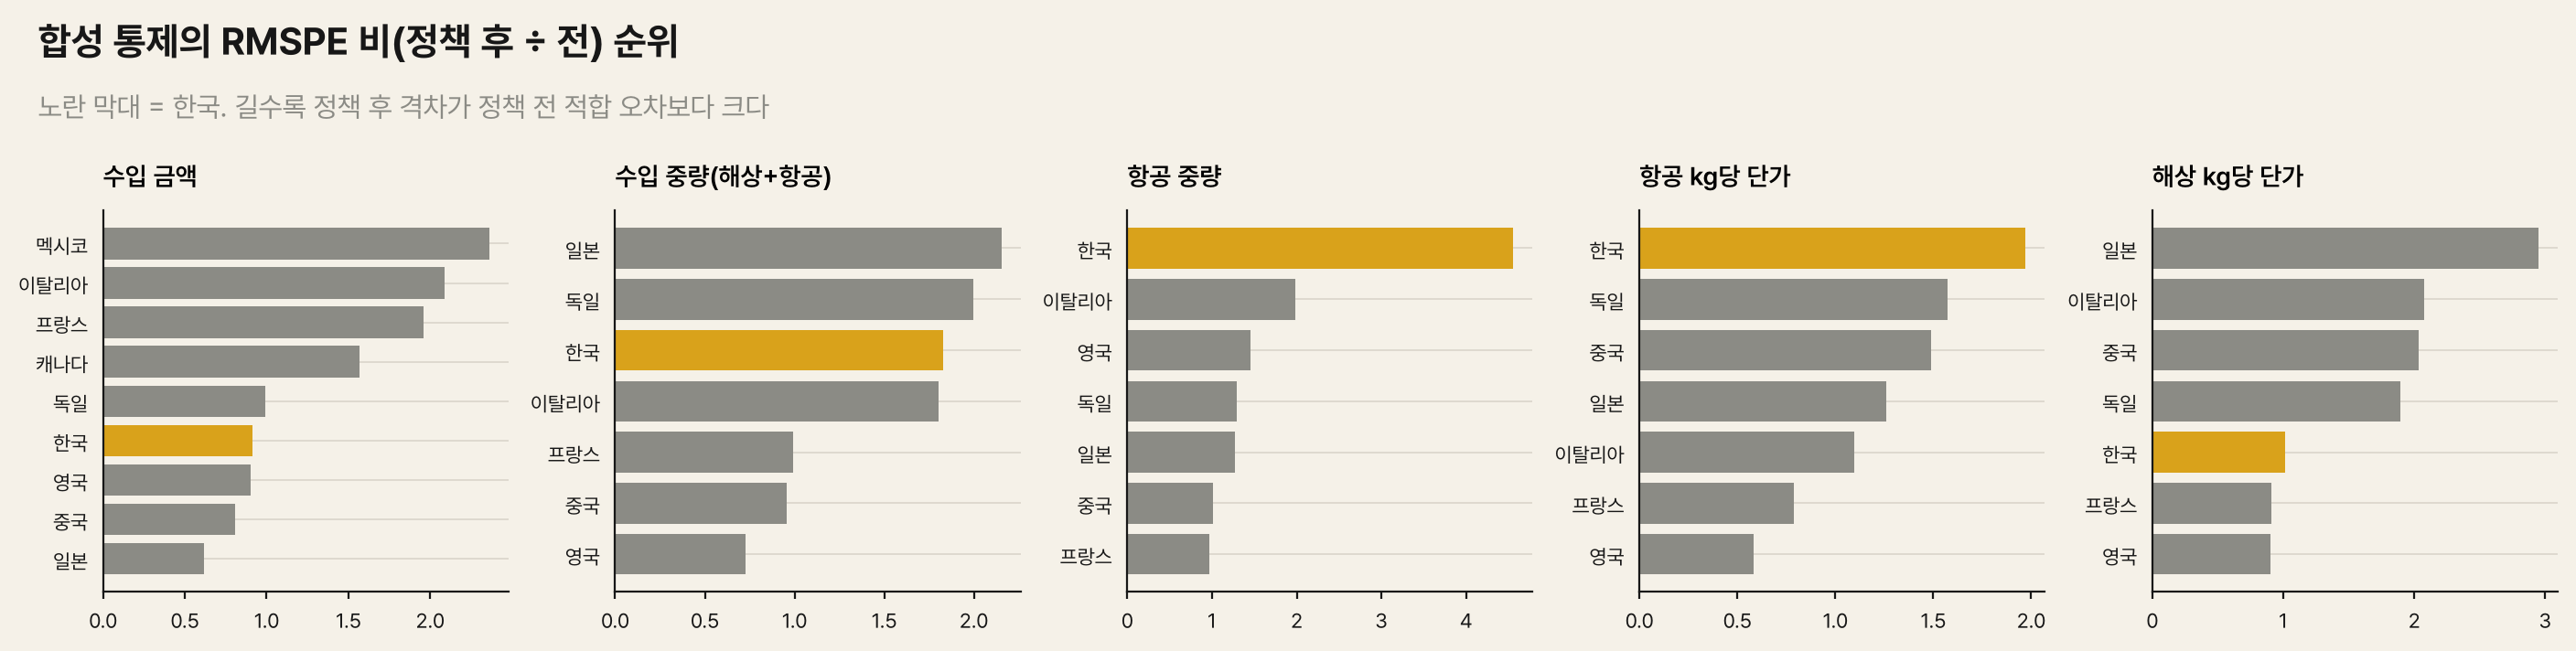

In [11]:
fig, axes = nbviz.figure((14, 4.0), 1, 5, title="합성 통제의 RMSPE 비(정책 후 ÷ 전) 순위", subtitle="노란 막대 = 한국. 길수록 정책 후 격차가 정책 전 적합 오차보다 크다")
for ax, m in zip(axes, cmp.METRICS):
    r = synth[m]["placebo_ratios"].sort_values()
    ax.barh([COUNTRY_KO.get(c, c) for c in r.index], r.values, color=[C["primary"] if c == cmp.TREATED else C["muted"] for c in r.index])
    ax.set_title(cmp.METRIC_KO[m], fontsize=10)
    ax.tick_params(labelsize=8)
plt.show()

**발견**:
- 정책 전 적합도(RMSPE)는 0.09~0.16이다. 항공 중량(0.098)과 해상 단가(0.087)는 잘 맞았고, 금액·중량·항공 단가는 0.15~0.16으로 덜 맞았다.
- 항공 중량과 항공 단가에서 한국의 정책 후/전 RMSPE 비(4.6, 2.0)는 7개국 중 1위다. 그러나 7개 단위의 순위 p는 1/7 = 0.14보다 작아질 수 없다.
- **합성 한국의 구성이 한쪽으로 쏠린 지표가 있다.** 수입 금액은 멕시코 54%, 항공 단가는 영국 53%다. 이런 지표의 합성 통제 결과는 그 한 나라의 사정에 크게 좌우된다.

**판단**: 합성 통제는 "한국의 항공 지표 이탈이 비교국 중 가장 크다"는 방향을 보여 주지만, 통계적 판정 근거로는 이중차분 위약보다 약하다.

### A2. 강건성: 결론이 선택에 좌우되지 않는가

분석자가 내린 선택을 하나씩 바꿔 β와 위약 p가 어떻게 움직이는지 본다.
- 비교국: 영국 제외, 중국 제외, (해상·항공 지표에) 캐나다·멕시코 포함
- 정책 시점: 2025-08(관세 적용 월), 2025-10
- 환율 통제 제외

In [12]:
def estimate(metric, drop=(), add_land=False, break_month=BREAK, use_fx=True):
    countries = [c for c in cmp.countries_for(metric, panel) if c not in drop]
    if add_land:
        countries += [c for c in cmp.LAND_BORDER if c not in countries]
    y = cmp.yoy(cmp.wide(panel, cmp.METRICS[metric][0], countries))
    fx = cmp.yoy(cmp.wide(panel, "lcu_per_usd", countries)).reindex(y.index) if use_fx else None
    p = cmp.placebo(y, cmp.TREATED, break_month, fx)
    return pd.Series({"beta": p["beta"], "p_space_time": p["p_space_time"]})

variants = {
    "기준": {},
    "영국 제외": {"drop": ("United Kingdom",)},
    "중국 제외": {"drop": ("China",)},
    "캐나다·멕시코 포함": {"add_land": True},
    "시점 2025-08": {"break_month": pd.Timestamp("2025-08-01")},
    "시점 2025-10": {"break_month": pd.Timestamp("2025-10-01")},
    "환율 통제 없음": {"use_fx": False},
}
rob = pd.concat({name: pd.DataFrame({cmp.METRIC_KO[m]: estimate(m, **kw) for m in cmp.METRICS}).T
                 for name, kw in variants.items()}, names=["variant", "metric"])
rob.unstack("variant").swaplevel(axis=1).sort_index(axis=1, level=0).loc[:, list(variants)]

variant          기준               영국 제외               중국 제외               \
               beta p_space_time   beta p_space_time   beta p_space_time   
metric                                                                     
수입 금액        -0.010        0.923  0.026        0.788 -0.016        0.827   
수입 중량(해상+항공)  0.112        0.451  0.163        0.282  0.112        0.577   
항공 중량         0.461        0.330  0.587        0.077  0.494        0.423   
항공 kg당 단가    -0.551        0.077 -0.623        0.026 -0.495        0.141   
해상 kg당 단가    -0.118        0.187 -0.125        0.205 -0.130        0.218   

variant      캐나다·멕시코 포함              시점 2025-08              시점 2025-10  \
                   beta p_space_time       beta p_space_time       beta   
metric                                                                    
수입 금액            -0.010        0.923     -0.021        0.821      0.028   
수입 중량(해상+항공)      0.159        0.496      0.146        0.308      0.105   
항공 중량             0.410        0.376      0.468        0.319      0.445   
항공 kg당 단가        -0.584        0.248     -0.558        0.066     -0.474   
해상 kg당 단가        -0.100        0.496     -0.161        0.077     -0.088   

variant                   환율 통제 없음               
             p_space_time     beta p_space_time  
metric                                           
수입 금액               0.769   -0.032        0.761  
수입 중량(해상+항공)        0.516    0.106        0.462  
항공 중량               0.341    0.457        0.319  
항공 kg당 단가           0.176   -0.562        0.099  
해상 kg당 단가           0.330   -0.115        0.209

In [13]:
# β만 한눈에: 행 = 지표, 열 = 변형
rob["beta"].unstack("variant")[list(variants)].style.format("{:+.3f}").background_gradient(cmap="RdBu", vmin=-0.8, vmax=0.8, axis=None)

variant,기준,영국 제외,중국 제외,캐나다·멕시코 포함,시점 2025-08,시점 2025-10,환율 통제 없음
metric,,,,,,,
수입 금액,-0.010,+0.026,-0.016,-0.010,-0.021,+0.028,-0.032
수입 중량(해상+항공),+0.112,+0.163,+0.112,+0.159,+0.146,+0.105,+0.106
항공 중량,+0.461,+0.587,+0.494,+0.410,+0.468,+0.445,+0.457
항공 kg당 단가,-0.551,-0.623,-0.495,-0.584,-0.558,-0.474,-0.562
해상 kg당 단가,-0.118,-0.125,-0.130,-0.100,-0.161,-0.088,-0.115


**발견**:
- **항공 kg당 단가**의 효과 크기는 모든 변형에서 −0.47~−0.62로 안정적이다. 방향과 크기는 분석 선택에 좌우되지 않는다.
- 그러나 **p값은 영국 포함 여부에 크게 좌우된다.** 영국을 빼면 0.026, 캐나다·멕시코를 넣으면 0.25다.
  영국이 한국 다음으로 크게 떨어진 나라여서, 영국을 빼면 한국이 상대적으로 더 특별해 보인다.
  어느 쪽이든 5개 지표에 Holm 보정을 하면 0.05를 넘는다(0.026 × 5 = 0.13).
- 정책 시점을 2025-08로 당겨도(p 0.066) 2025-10으로 미뤄도(p 0.18) 결론은 같다.
- 항공 중량은 영국을 빼면 p 0.077로 내려가지만, 역시 기준에는 못 미친다.
- 수입 금액은 모든 변형에서 0 근처다(−0.03 ~ +0.03). **"한국 특유의 금액 변화 없음"은 강건한 결론이다.**

**판단**: 사후에 비교국을 빼서 p를 0.05 아래로 만드는 것은 사전 등록이 막으려는 행동이다. 이 결과는 강건성 점검으로만 보고하고, 판정은 사전 등록한 기준 분석을 따른다.

### A3. 일치 확인

이 노트북의 기준 추정치가 `scripts/run_all.py`가 만든 표(`reports/tables/comparison_did.csv`)와 같은지 확인한다. 다르면 이 셀이 실패한다.

In [14]:
saved = pd.read_csv(TABLES_DIR / "comparison_did.csv").set_index("metric")
assert np.allclose(saved.loc[list(cmp.METRICS), "beta_fx_adjusted"], inf["beta"].astype(float), atol=1e-9)
assert np.allclose(saved.loc[list(cmp.METRICS), "p_space_time"], inf["p_space_time"].astype(float), atol=1e-12)
print("notebook estimates match reports/tables/comparison_did.csv")

notebook estimates match reports/tables/comparison_did.csv
